# Phase 6: Severity Model, Gamma GLM and GAM

**Business question this phase serves:** *given a claim happened, how large is it expected to be?*
This is the second building block of the technical premium (Phase 7: technical premium = frequency x
severity). Severity is only defined for the 14,792 training policies with at least one paid claim, a
much smaller dataset than frequency's, which limits how much signal can be extracted.

**Inputs:** [`data/processed/train.parquet`](../data/processed/train.parquet),
[`val.parquet`](../data/processed/val.parquet), and
[`models/feature_encoder.joblib`](../models/feature_encoder.joblib) (Phase 3).

**What this notebook does:**
1. Determine a data-driven large-loss threshold and split severity into an "attritional" layer (capped,
   modeled) and a "large-loss" layer (spread as a flat loading, the standard treatment for a population
   too sparse to differentiate by rating factor).
2. Fit a Gamma GLM on the attritional layer, weighted for policies with more than one claim, with the
   same factor-level stepwise selection as Phase 4.
3. Fit a Gamma GAM as a benchmark, with the same protocol as Phase 5.
4. Compare both with a naive baseline out of sample.
5. State what Phase 7 should use.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")  # pygam's benign IRLS runtime warnings, as in Phase 5


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.pipeline import get_severity_subset
from src.models.frequency_glm import build_factor_groups, relativities_table
from src.models.frequency_gam import GAMFeatureBuilder
from src.models.severity_glm import (
    determine_large_loss_threshold,
    cap_severity,
    large_loss_loading,
    fit_gamma_glm,
    backward_stepwise_selection_gamma,
)
from src.models.severity_gam import fit_gamma_gam
from src.models.glm_diagnostics import (
    deviance_summary,
    out_of_sample_pseudo_r2_gamma,
    calibration_by_decile,
    plot_calibration_by_decile,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")
val_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "val.parquet")
encoder = joblib.load(PROJECT_ROOT / "models" / "feature_encoder.joblib")

sev_train = get_severity_subset(train_df)
sev_val = get_severity_subset(val_df)
print(f"Severity training rows: {len(sev_train):,}  |  validation rows: {len(sev_val):,}")
print(f"(compare to frequency's {len(train_df):,} / {len(val_df):,}: an order of magnitude less data)")

Severity training rows: 14,792  |  validation rows: 4,928
(compare to frequency's 401,175 / 133,725: an order of magnitude less data)


## 1. Large-loss threshold and the attritional/excess split

Phase 1/2 already found this dataset's severity is heavily right-skewed (median EUR 1,172, but a single
claim reaches EUR 4.08M). A Gamma GLM's mean is estimated by maximum likelihood, and a handful of
enormous claims can distort every coefficient for the whole book: the standard actuarial answer is to
**cap** claims at a data-driven threshold for the "attritional" model that differentiates by rating
factor, and add back the average cost of the excess as a **flat, portfolio-wide loading**: the same
logic as estimating a reinsurance excess-of-loss layer's burning cost: the large-loss population is too
sparse here (very few claims) to credibly say *whose* claim will be huge, so its average cost is spread
evenly instead of modeled by segment.

In [2]:
threshold = determine_large_loss_threshold(sev_train, percentile=0.99)
print(f"Large-loss threshold (99th percentile of training severity): EUR {threshold:,.0f}")

n_large = (sev_train["AvgClaimAmount"] > threshold).sum()
print(f"Training claims above threshold: {n_large} of {len(sev_train)} ({n_large / len(sev_train):.2%})")

loading = large_loss_loading(train_df, sev_train, threshold)
print(f"\nLarge-loss loading: EUR {loading:.2f} per policy-year")
print("(added to every policy's technical premium in Phase 7, not differentiated by rating factor)")

Large-loss threshold (99th percentile of training severity): EUR 15,000
Training claims above threshold: 146 of 14792 (0.99%)

Large-loss loading: EUR 33.54 per policy-year
(added to every policy's technical premium in Phase 7, not differentiated by rating factor)


**Reading:** the 99th percentile of training severity is EUR 15,000 (a round settlement amount);
146 training claims are above it. Their excess cost, spread over the whole training exposure, gives a
loading of EUR 33.54 per policy-year, added to every policy regardless of segment.

## 2. Attritional severity: Gamma GLM

In [3]:
y_train_capped = cap_severity(sev_train, threshold)
weights_train = sev_train["sev_claim_count"]

X_sev_train = encoder.transform(sev_train)
full_results = fit_gamma_glm(X_sev_train, y_train_capped, weights_train)
print(deviance_summary(full_results))

{'n_obs': 14792, 'df_model': 37, 'df_resid': 14754, 'log_likelihood': np.float64(-125173.8452223824), 'deviance': np.float64(15030.063666695596), 'null_deviance': np.float64(15249.716125737119), 'aic': np.float64(250423.6904447648), 'pseudo_r2_deviance': np.float64(0.014403708057936448)}


**Reading:** an in-sample pseudo-R² of 1.4%, weaker than the frequency GLM's 4.1% (Phase 4), on a
dataset more than twenty times smaller (14,792 vs. 401,175 rows). Severity may simply be harder to
differentiate with the factors available here; the out-of-sample check below decides.

In [4]:
feature_groups = build_factor_groups(list(X_sev_train.columns))
final_results, remaining_groups, history = backward_stepwise_selection_gamma(
    X_sev_train, y_train_capped, weights_train, feature_groups, p_threshold=0.05, verbose=True
)
print(f"\nFactors kept: {list(remaining_groups.keys())}")
print(history)

Step 1: drop 'DrivAge' (LR-test p=1.0000, AIC 250423.7 -> 250413.1)


Step 2: drop 'Density' (LR-test p=1.0000, AIC 250413.1 -> 250410.3)


Step 3: drop 'VehGas' (LR-test p=1.0000, AIC 250410.3 -> 250407.7)



Factors kept: ['BonusMalus', 'VehPower', 'VehAge', 'VehBrand', 'Region']
   step factor_removed  lr_test_p_value   aic_before    aic_after
0     1        DrivAge           1.0000 250,423.6904 250,413.0875
1     2        Density           1.0000 250,413.0875 250,410.2765
2     3         VehGas           1.0000 250,410.2765 250,407.7427


**Finding:** unlike frequency (Phase 4, where all 8 factors were kept), stepwise selection drops
**`DrivAge`**, **`Density`** and **`VehGas`** (no evidence of an effect on attritional severity once
the other factors are controlled for). For `VehGas`, Phase 2's univariate gap in *mean* severity
(Regular above Diesel) does not survive capping and controlling for `VehBrand` and `Region`: it was
driven by a few large claims and by the brand/region mix of each fuel type, not by fuel type itself.

## 3. Relativities: reading the kept factors

In [5]:
relativities = relativities_table(final_results)
print("Top 10 (highest predicted severity, relative to baseline):")
display(relativities[["coefficient", "p_value", "relativity"]].head(10))
print("\nBottom 10 (lowest predicted severity, relative to baseline):")
display(relativities[["coefficient", "p_value", "relativity"]].tail(10))

Top 10 (highest predicted severity, relative to baseline):


,coefficient,p_value,relativity
const,7.1063,0.0000,"1,219.6636"
Region_R94,0.3729,0.0139,1.4520
Region_R43,0.3136,0.2430,1.3684
Region_R93,0.2571,0.0000,1.2932
Region_R91,0.2172,0.0009,1.2426
Region_R21,0.2042,0.2868,1.2265
Region_R41,0.1505,0.0934,1.1624
Region_R23,0.1034,0.4053,1.1089
Region_R72,0.0977,0.1296,1.1027
Region_R26,0.0955,0.3330,1.1002



Bottom 10 (lowest predicted severity, relative to baseline):


,coefficient,p_value,relativity
VehBrand_B13,-0.0107,0.8912,0.9893
VehBrand_B11,-0.0135,0.8547,0.9866
VehBrand_B5,-0.0154,0.7502,0.9847
Region_R73,-0.0244,0.8057,0.9759
Region_R22,-0.0275,0.7892,0.9728
VehBrand_B6,-0.0802,0.1388,0.9229
VehBrand_B4,-0.0891,0.1119,0.9148
Region_R83,-0.1241,0.4024,0.8833
Region_R42,-0.3612,0.0572,0.6969
VehBrand_B14,-0.3820,0.0123,0.6825


**Reading:** `BonusMalus`, `VehPower`, `VehAge`, `VehBrand` and `Region` are kept, but several of the
largest relativities belong to small regions (e.g. `Region_R94`, `Region_R43`) with few claims behind
them. With about 15,000 severity observations spread over 22 regions and 11 brands, those cells have
low credibility.

## 4. Severity GAM: the benchmark

Same protocol as Phase 5: `GAMFeatureBuilder` (reused as-is: it has no severity-specific logic) builds
smooth-spline-ready features, `fit_gamma_gam` fits with the same `sev_claim_count` weighting as the
GLM. Unlike the frequency GAM, this dataset is small enough (~15,000 rows) that no memory-constrained
fallback strategy is needed: a full fit is fast and low-risk.

In [6]:
gam_builder = GAMFeatureBuilder().fit(train_df, vehage_cap=encoder.vehage_cap_)
X_sev_train_gam = gam_builder.transform(sev_train)

import time
t0 = time.time()
gam = fit_gamma_gam(X_sev_train_gam, y_train_capped.to_numpy(), weights_train.to_numpy(), n_splines=8)
print(f"GAM fit time: {time.time() - t0:.2f}s")
print(f"In-sample pseudo-R^2 (pygam's own statistic): {gam.statistics_['pseudo_r2']['explained_deviance']:.4f}")

GAM fit time: 1.15s
In-sample pseudo-R^2 (pygam's own statistic): 0.0190


## 5. Out-of-sample comparison

Both models are scored on `sev_val` (the validation severity subset, not used for fitting) with the same
Gamma-deviance pseudo-R² (`glm_diagnostics.out_of_sample_pseudo_r2_gamma`). The validation target is
capped at the same threshold as training.

In [7]:
X_sev_val_glm = encoder.transform(sev_val)
X_sev_val_glm_const = sm.add_constant(X_sev_val_glm[final_results.model.exog_names[1:]], has_constant="add")
pred_glm_val = final_results.predict(X_sev_val_glm_const)

X_sev_val_gam = gam_builder.transform(sev_val)
pred_gam_val = gam.predict(X_sev_val_gam)

y_val_capped = cap_severity(sev_val, threshold).to_numpy()
weights_val = sev_val["sev_claim_count"].to_numpy()

glm_r2 = out_of_sample_pseudo_r2_gamma(y_val_capped, pred_glm_val, weights_val)
gam_r2 = out_of_sample_pseudo_r2_gamma(y_val_capped, pred_gam_val, weights_val)

# The simplest possible baseline: predict the overall training average severity for every claim.
naive_pred = np.full_like(y_val_capped, np.average(y_train_capped, weights=weights_train))
naive_r2 = out_of_sample_pseudo_r2_gamma(y_val_capped, naive_pred, weights_val)

print(f"{'Model':<28}{'Validation pseudo-R^2':>24}")
print(f"{'Naive (overall average)':<28}{naive_r2['pseudo_r2']:>23.2%} ")
print(f"{'Gamma GLM':<28}{glm_r2['pseudo_r2']:>23.2%} ")
print(f"{'Gamma GAM':<28}{gam_r2['pseudo_r2']:>23.2%} ")

Model                          Validation pseudo-R^2
Naive (overall average)                      -0.11% 
Gamma GLM                                    -0.09% 
Gamma GAM                                     0.04% 


**Finding:** the three rows are practically the same. The naive "training average" baseline scores
-0.11%, the GLM -0.09% and the GAM +0.04%: neither model improves meaningfully on a flat average once
measured on data it was not fitted on, although both fit their training data slightly better (in-sample
1.4% for the GLM, 1.9% for the GAM).

This is a common result in motor pricing: the available rating factors (`BonusMalus`, `DrivAge`,
vehicle characteristics) differentiate *claim occurrence* well, with no strong reason to also
differentiate *claim size given occurrence*; Phase 2 already showed that frequency and severity drivers
differ. Severity also has far less training data (14,792 vs. 401,175 rows) for a comparable number of
parameters.

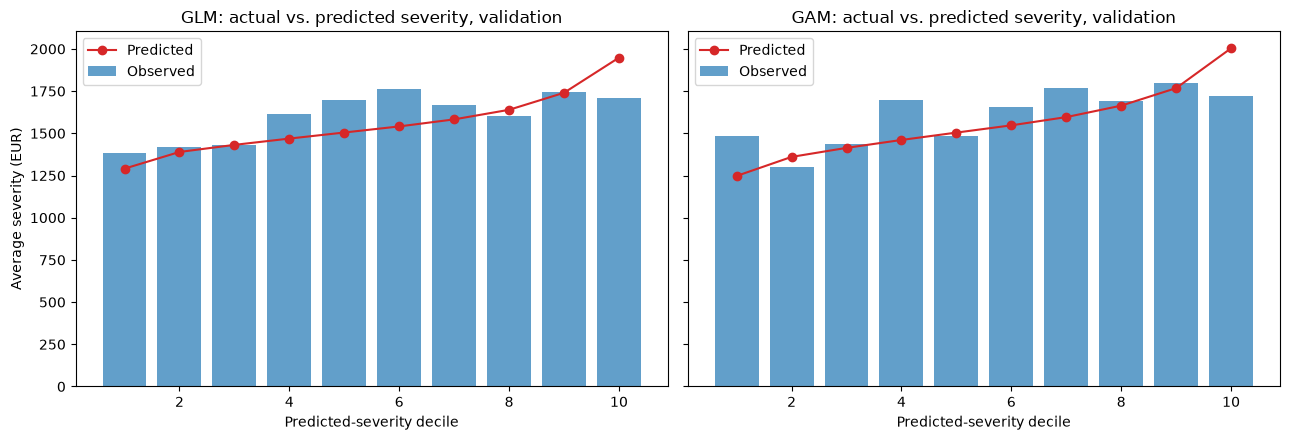

In [8]:
decile_glm = calibration_by_decile(y_val_capped, pred_glm_val, weights_val, n_bins=10)
decile_gam = calibration_by_decile(y_val_capped, pred_gam_val, weights_val, n_bins=10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, decile_df, name in [(ax1, decile_glm, "GLM"), (ax2, decile_gam, "GAM")]:
    ax.bar(decile_df["bin"], decile_df["observed"], color="#1f77b4", alpha=0.7, label="Observed")
    ax.plot(decile_df["bin"], decile_df["predicted"], color="#d62728", marker="o", label="Predicted")
    ax.set_title(f"{name}: actual vs. predicted severity, validation")
    ax.set_xlabel("Predicted-severity decile")
    ax.legend()
ax1.set_ylabel("Average severity (EUR)")
fig.tight_layout()
plt.show()

**Reading:** both charts show some ordering (higher predicted deciles tend to show higher observed
severity), but the relationship is noisy, and the difference from the naive baseline is within what
sampling variation could produce at this data size.

## 6. What this means for Phase 7

- **Use the Gamma GLM's fitted severity.** It is not measurably better than the naive average on this
  validation split, but not worse either (-0.09% vs. -0.11%), and its relativities are plausible. The GAM
  is not retained: no measured advantage, and less interpretable.
- **Add the flat large-loss loading** (Section 1) uniformly: rare large claims are priced for, but not
  differentiated by segment, given how sparse they are.
- **The technical premium's risk differentiation comes almost entirely from frequency.**

## 7. Save the models

In [9]:
models_dir = PROJECT_ROOT / "models"
joblib.dump(
    {
        "results": final_results,
        "feature_columns": final_results.model.exog_names[1:],
        "large_loss_threshold": threshold,
        "large_loss_loading": loading,
    },
    models_dir / "sev_glm.pkl",
)
joblib.dump({"gam": gam, "feature_builder": gam_builder, "large_loss_threshold": threshold}, models_dir / "sev_gam.pkl")
print(f"Saved: {(models_dir / 'sev_glm.pkl').relative_to(PROJECT_ROOT).as_posix()}")
print(f"Saved: {(models_dir / 'sev_gam.pkl').relative_to(PROJECT_ROOT).as_posix()}")

Saved: models/sev_glm.pkl
Saved: models/sev_gam.pkl


## Phase 6 summary

| Check | Result |
|---|---|
| Large-loss threshold (99th pct, train) | EUR 15,000 |
| Large-loss loading | EUR 33.54 per policy-year, flat across the portfolio |
| Stepwise selection (GLM) | Drops `DrivAge`, `Density` and `VehGas`; the univariate fuel-type gap in mean severity does not survive capping and controls |
| In-sample pseudo-R² | GLM 1.4%, GAM 1.9%, both weaker than frequency's GLM (4.1%) on far less data |
| **Out-of-sample pseudo-R²** | Naive -0.11%, GLM -0.09%, GAM +0.04%: no model measurably beats the naive average |
| Phase 7 guidance | Gamma GLM + flat large-loss loading; risk differentiation comes almost entirely from frequency |

**Output:** [`models/sev_glm.pkl`](../models/sev_glm.pkl), [`models/sev_gam.pkl`](../models/sev_gam.pkl), ready for
**Phase 7: technical premium and model diagnostics**.